# 09 — RL değerlendirmesi (Ders 9.4)
PPO / SAC (5'er tohum) Aşama 6 düzeneğinde, tam durumlu klasiklerle aynı blokta. Kararlar: `KARARLAR.md` → Aşama 9.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'cartpole.py').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import importlib, warnings, controllers, evaluate as ev
from controllers import *
import cartpole as cp
for mod in (cp, controllers, ev): importlib.reload(mod)
import torch; torch.set_num_threads(1)
warnings.filterwarnings("ignore", category=DeprecationWarning)

P = cp.CartPoleParams(); A, B = cp.analytic_AB(P); dt = 0.02; A_d, B_d = cp.discretize(A, B, dt)
q = np.diag([4.0, 1.0, 25.0, 1.0])
K_bry, P_bry = lqr_discrete(A_d, B_d, q, np.array([[0.01]]), dt)
K_r10, _     = lqr_discrete(A_d, B_d, q, np.array([[0.1]]),  dt)

# Tam durumlu klasikler (RL de tam durum görüyor)
klasikler = [
    ("Kaskad PID", lambda: CascadePID()),
    ("LQR Bryson", lambda: LQRController(K_bry)),
    ("LQR R×10",   lambda: LQRController(K_r10)),
    ("MPC N=10",   lambda: MPCController(A_d, B_d, q, np.array([[0.01]]), P_bry, N=10, dt=dt, K_yedek=K_bry)),
]

## Öğrenme eğrileri (zor geliştirme bloğu, deterministik sınav)

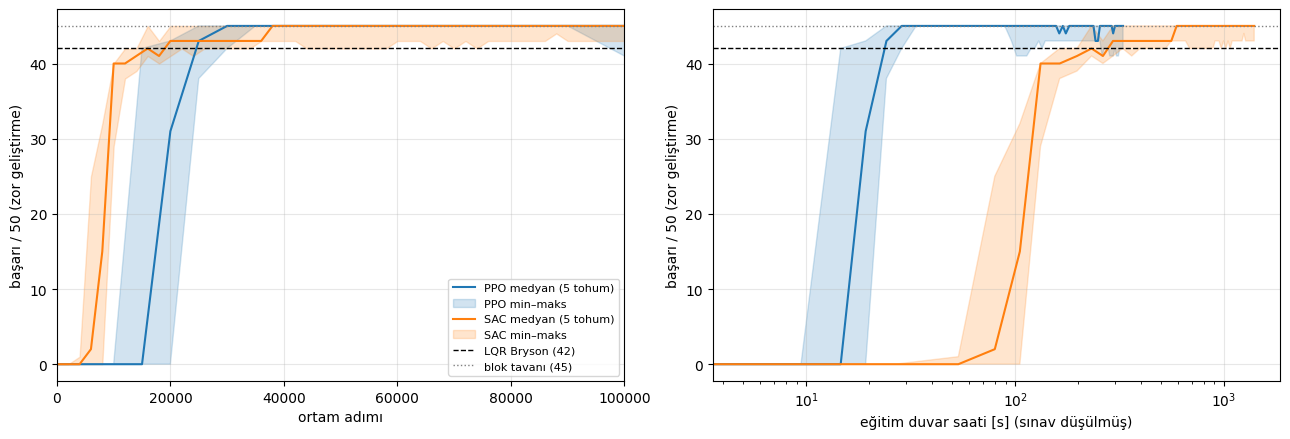

In [2]:
import glob, matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for algo, renk in [("ppo", "C0"), ("sac", "C1")]:
    D = [np.genfromtxt(f, delimiter=",", names=True) for f in sorted(glob.glob(str(ROOT / f"runs/{algo}_seed*/sinav.csv")))]
    B = np.array([d["basari"] for d in D])              # (5 tohum, sınav sayısı)
    W = np.array([d["duvar_egitim_s"] for d in D])
    for ax, x in [(axes[0], D[0]["adim"]), (axes[1], np.median(W, axis=0))]:
        ax.plot(x, np.median(B, axis=0), color=renk, label=f"{algo.upper()} medyan (5 tohum)")
        ax.fill_between(x, B.min(axis=0), B.max(axis=0), color=renk, alpha=0.2, label=f"{algo.upper()} min–maks")
for ax in axes:
    ax.axhline(42, ls="--", c="k", lw=1, label="LQR Bryson (42)")
    ax.axhline(45, ls=":", c="gray", lw=1, label="blok tavanı (45)")
    ax.set_ylabel("başarı / 50 (zor geliştirme)"); ax.grid(alpha=0.3)
axes[0].set_xlabel("ortam adımı"); axes[0].set_xlim(0, 100_000)
axes[1].set_xlabel("eğitim duvar saati [s] (sınav düşülmüş)"); axes[1].set_xscale("log")
axes[0].legend(fontsize=8); plt.tight_layout()
plt.savefig("09_ogrenme_egrileri.png", dpi=110)

## Değerlendirme: klasikler + 20 RL politikası (5 tohum × {en_iyi, son} × 2 algoritma)

In [3]:
rl = [(f"{algo.upper()} s{k} {hangi}", rl_yukle(ROOT / f"runs/{algo}_seed{k}", hangi))
      for algo in ("ppo", "sac") for k in range(5) for hangi in ("en_iyi", "son")]

sonuclar = {}
for blok_adi in ("nominal", "zor"):
    blok = ev.senaryolar(blok_adi, 50, seed=0)              # GELİŞTİRME bloğu
    satirlar = []
    for ad, yap in klasikler + rl:
        satirlar += ev.degerlendir(ad, yap, blok)
    sonuclar[blok_adi] = satirlar
    print(f"\n=== {blok_adi.upper()} blok (geliştirme, 50 senaryo) ===")
    ev.ozet_yazdir(ev.ozet(satirlar))
    ev.csv_yaz(satirlar, f"sonuclar_{blok_adi}_rl.csv")


=== NOMINAL blok (geliştirme, 50 senaryo) ===
kontrolcü        |  başarı |    %95 Wilson | oturma med | efor med | max|x| | son|x| med
Kaskad PID       |  50/50  | [0.93, 1.00] |     3.02 s |      5.7 |   0.71 |    0.00 cm
LQR Bryson       |  50/50  | [0.93, 1.00] |     2.15 s |      2.9 |   0.66 |    0.00 cm
LQR R×10         |  50/50  | [0.93, 1.00] |     2.31 s |      1.7 |   0.68 |    0.00 cm
MPC N=10         |  50/50  | [0.93, 1.00] |     2.15 s |      2.9 |   0.66 |    0.00 cm
PPO s0 en_iyi    |  50/50  | [0.93, 1.00] |    10.00 s |      2.8 |   0.70 |   16.07 cm
PPO s0 son       |  50/50  | [0.93, 1.00] |    10.00 s |      4.8 |   0.66 |    9.59 cm
PPO s1 en_iyi    |  50/50  | [0.93, 1.00] |    10.00 s |      2.8 |   0.69 |    7.93 cm
PPO s1 son       |  50/50  | [0.93, 1.00] |    10.00 s |      4.3 |   0.67 |    5.52 cm
PPO s2 en_iyi    |  50/50  | [0.93, 1.00] |     3.29 s |      3.7 |   0.67 |    0.62 cm
PPO s2 son       |  50/50  | [0.93, 1.00] |     2.32 s |      2.3 |   0.

c:\Users\USER\miniconda3\envs\GNC_env\lib\site-packages\cvxpy\problems\problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(



=== ZOR blok (geliştirme, 50 senaryo) ===
kontrolcü        |  başarı |    %95 Wilson | oturma med | efor med | max|x| | son|x| med
Kaskad PID       |  45/50  | [0.79, 0.96] |     3.72 s |     38.6 |  10.84 |    0.00 cm
LQR Bryson       |  42/50  | [0.71, 0.92] |     2.49 s |     19.0 | 389.64 |    0.00 cm
LQR R×10         |  45/50  | [0.79, 0.96] |     2.80 s |     14.1 | 376.22 |    0.00 cm
MPC N=10         |  43/50  | [0.74, 0.93] |     2.54 s |     19.0 | 389.13 |    0.00 cm
PPO s0 en_iyi    |  45/50  | [0.79, 0.96] |    10.00 s |     13.3 | 298.65 |   16.10 cm
PPO s0 son       |  43/50  | [0.74, 0.93] |    10.00 s |     17.2 |   9.80 |    9.59 cm
PPO s1 en_iyi    |  45/50  | [0.79, 0.96] |    10.00 s |     12.6 | 441.04 |    7.92 cm
PPO s1 son       |  45/50  | [0.79, 0.96] |    10.00 s |     14.1 |   7.26 |    5.52 cm
PPO s2 en_iyi    |  45/50  | [0.79, 0.96] |     4.74 s |     15.2 | 330.06 |    0.62 cm
PPO s2 son       |  42/50  | [0.71, 0.92] |     3.65 s |     13.2 | 357.33 |

## Tohumlar arası özet
Örnek birimi **tohum**: tohum başına bir sayı → medyan [min, maks]. Son |x| yalnız başarılı bölümlerde.

In [4]:
tab = {b: ev.ozet(sonuclar[b]) for b in sonuclar}
for b in ("nominal", "zor"):
    print(f"\n--- {b} ---")
    for ad, _ in klasikler:
        o = tab[b][ad]
        print(f"{ad:16s}: başarı {o['basari']:2d}             son|x| {o['son_x_medyan']*100:5.2f} cm            efor {o['efor_medyan']:5.1f}")
    for algo in ("PPO", "SAC"):
        for hangi in ("en_iyi", "son"):
            O = [tab[b][f"{algo} s{k} {hangi}"] for k in range(5)]
            bs = np.array([o["basari"] for o in O])
            sx = np.array([o["son_x_medyan"] for o in O]) * 100
            ef = np.array([o["efor_medyan"] for o in O])
            print(f"{algo} {hangi:7s}     : başarı {np.median(bs):2.0f} [{bs.min()}, {bs.max()}]   "
                  f"son|x| {np.median(sx):5.2f} cm [{sx.min():.2f}, {sx.max():.2f}]   efor {np.median(ef):5.1f} [{ef.min():.1f}, {ef.max():.1f}]")


--- nominal ---
Kaskad PID      : başarı 50             son|x|  0.00 cm            efor   5.7
LQR Bryson      : başarı 50             son|x|  0.00 cm            efor   2.9
LQR R×10        : başarı 50             son|x|  0.00 cm            efor   1.7
MPC N=10        : başarı 50             son|x|  0.00 cm            efor   2.9
PPO en_iyi      : başarı 50 [50, 50]   son|x|  8.39 cm [0.62, 16.07]   efor   2.8 [2.8, 3.7]
PPO son         : başarı 50 [50, 50]   son|x|  0.90 cm [0.25, 9.59]   efor   4.3 [2.3, 4.8]
SAC en_iyi      : başarı 50 [50, 50]   son|x|  1.05 cm [0.60, 9.08]   efor   3.1 [2.7, 4.0]
SAC son         : başarı 50 [50, 50]   son|x|  0.74 cm [0.16, 1.87]   efor   3.3 [2.8, 3.7]

--- zor ---
Kaskad PID      : başarı 45             son|x|  0.00 cm            efor  38.6
LQR Bryson      : başarı 42             son|x|  0.00 cm            efor  19.0
LQR R×10        : başarı 45             son|x|  0.00 cm            efor  14.1
MPC N=10        : başarı 43             son|x|  0.00 cm

## Hangi senaryolar? (zor blok, en_iyi modeller)
Aşama 6 göstergesi: |θ + θ̇/λ| (λ = A'nın kararsız özdeğeri) > 0.6 → hiçbir kontrolcü kurtaramıyordu.

In [5]:
Z = sonuclar["zor"]
blok_zor = ev.senaryolar("zor", 50, seed=0)
lam = np.max(np.linalg.eigvals(A).real)
def basari(ad): return np.array([r["basari"] for r in Z if r["kontrolcu"] == ad])
def gosterge(i): s0 = blok_zor[i]["s0"]; return abs(s0[2] + s0[3] / lam)

lqr = basari("LQR Bryson")
for algo in ("PPO", "SAC"):
    say = sum(basari(f"{algo} s{k} en_iyi").astype(int) for k in range(5))     # her senaryoda kaç tohum başardı (0–5)
    kurtarir = np.where(~lqr & (say >= 3))[0]; kaybeder = np.where(lqr & (say <= 2))[0]; kimse = np.where(~lqr & (say == 0))[0]
    print(f"{algo}: LQR ✗, RL ≥3/5 → {[(int(i), int(say[i])) for i in kurtarir]}   gösterge {[round(gosterge(i), 2) for i in kurtarir]}")
    print(f"{algo}: LQR ✓, RL ≤2/5 → {[(int(i), int(say[i])) for i in kaybeder]}")
    print(f"{algo}: LQR ✗, RL 0/5  → {kimse.tolist()}   gösterge {[round(gosterge(i), 2) for i in kimse]}")

PPO: LQR ✗, RL ≥3/5 → [(13, 5), (26, 5), (47, 5)]   gösterge [np.float64(0.54), np.float64(0.59), np.float64(0.54)]
PPO: LQR ✓, RL ≤2/5 → []
PPO: LQR ✗, RL 0/5  → [0, 4, 21, 39, 48]   gösterge [np.float64(0.76), np.float64(0.73), np.float64(0.74), np.float64(0.62), np.float64(0.61)]
SAC: LQR ✗, RL ≥3/5 → [(13, 5), (26, 5), (47, 5)]   gösterge [np.float64(0.54), np.float64(0.59), np.float64(0.54)]
SAC: LQR ✓, RL ≤2/5 → []
SAC: LQR ✗, RL 0/5  → [0, 4, 21, 39, 48]   gösterge [np.float64(0.76), np.float64(0.73), np.float64(0.74), np.float64(0.62), np.float64(0.61)]
